# 🧪 Sandbox 2: การทดลอง Acoustic Echo Cancellation เชิงประจักษ์
### ผสานฟังก์ชันที่เวิร์กของเพื่อน + โมดูลที่เราพัฒนาขึ้นเอง + ประชันมาตรฐานสากล

**วิชา:** 517354 Digital Signal Processing (DSP)  
**ภาควิชาคอมพิวเตอร์ คณะวิทยาศาสตร์ มหาวิทยาลัยศิลปากร**

---

### 🤝 ฟังก์ชันที่นำมาผสานร่วมกัน:
* **ฟังก์ชันที่หยิบมาจากเพื่อนที่เวิร์ก (จาก `src.common.dsp_utils`):**
  - `check_eda`: ตรวจสอบและแสดงผลพารามิเตอร์สัญญาณ Sampling Rate, Nyquist, Sampling Interval
  - `add_noise`: เติมสัญญาณรบกวนไมโครโฟนตามระดับ SNR (dB) ที่กำหนด
  - `correlation_offset`: ตรวจหาตำแหน่งความหน่วงเวลาเสียงสะท้อน (Echo Lag) ด้วย Cross-Correlation
  - `shift_signal`: เลื่อนชดเชยสัญญาณตามค่า Lag ที่ตรวจพบ
  - `iir_filter`: ตัวกรอง IIR อเนกประสงค์ (Butterworth, Chebyshev)
* **ฟังก์ชันหลักที่เราพัฒนาขึ้นเอง (จาก `src` modules):**
  - `get_scenario_audio`, `create_fixed_room_ir`, `simulate_static_room_echo`: จำลองอะคูสติกห้องและดึงชุดข้อมูลเสียงจริง
  - `nlms_filter`, `lms_filter`: ตัวกรองปรับตัวได้ Pure NumPy พร้อมการชดเชย Bulk Delay
  - `calculate_erle`, `calculate_erle_curve`: คำนวณตัวชี้วัดการลดทอนเสียงสะท้อน (Echo Return Loss Enhancement)
  - `calculate_rmse`: คำนวณความคลาดเคลื่อนเทียบกับสัญญาณเป้าหมาย

---

### 🗺️ ลำดับการทดลอง 6 ขั้นตอน:
1. **ส่วนที่ 1: Sine Wave, check_eda, Magnitude Spectrum, การเลื่อนเวลา และการซ้อนทับ**
2. **ส่วนที่ 2: ค้นหาจุดเกิดเสียงสะท้อน (Echo Lag Detection) ด้วย `correlation_offset`**
3. **ส่วนที่ 3: ทดสอบตัวกรองจาก Lab (กลุ่มที่ใช้การไม่ได้ด้วย `iir_filter` vs กลุ่มที่พอใช้ได้)**
4. **ส่วนที่ 4: โหลดเสียงคนพูดจริง จำลอง Echo และผสมเสียงรบกวนด้วย `add_noise`**
5. **ส่วนที่ 5: กรองด้วยพระเอก `nlms_filter` ของเราเทียบกับ `lms_filter` และวัดผลด้วย `calculate_erle`**
6. **ส่วนที่ 6: Grand Comparison — ประชัน 3 ฝ่าย (STFT vs พระเอก NLMS vs มาตรฐานสากล `padasip`)**


---
## ⚙️ ส่วนที่ 0: นำเข้าฟังก์ชันที่เราทำเองและฟังก์ชันของเพื่อน


In [1]:
%matplotlib inline
import sys
from pathlib import Path
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy.signal as signal
from scipy.signal import savgol_filter
from sklearn.decomposition import FastICA
import padasip as pa
import IPython.display as ipd

# ตั้งค่าฟอนต์ภาษาไทยสำหรับกราฟ
matplotlib.rcParams['font.family'] = ['Tahoma', 'Leelawadee UI', 'DejaVu Sans']
matplotlib.rcParams['axes.unicode_minus'] = False

# เชื่อมพาธโปรเจกต์
PROJECT_ROOT = Path("C:/Users/khaok/69-1/DSP/FinalProject")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# ------------------------------------------------------------------------------
# 1. ฟังก์ชันที่หยิบมาจากเพื่อนที่เวิร์ก (จาก ProjectDSPFinal -> src.common.dsp_utils)
# ------------------------------------------------------------------------------
from src.common.dsp_utils import (
    check_eda,
    add_noise,
    correlation_offset,
    shift_signal,
    iir_filter,
)

# ------------------------------------------------------------------------------
# 2. ฟังก์ชันหลักที่เราพัฒนาขึ้นเอง (จาก src modules)
# ------------------------------------------------------------------------------
from src.simulation.room_simulator import (
    create_fixed_room_ir,
    simulate_static_room_echo,
    get_scenario_audio,
)
from src.adaptive_filters import nlms_filter, lms_filter
from src.metrics import calculate_erle, calculate_erle_curve, calculate_rmse

print("✅ โหลดฟังก์ชันของเราและฟังก์ชันของเพื่อนสำเร็จ พร้อมใช้งาน!")


✅ โหลดฟังก์ชันของเราและฟังก์ชันของเพื่อนสำเร็จ พร้อมใช้งาน!


---
## 🌊 ส่วนที่ 1: Sine Wave, check_eda, Magnitude Spectrum, การเลื่อนเวลา และการซ้อนทับ
* **รันฟังก์ชัน `check_eda` ของเพื่อน:** สำรวจคุณลักษณะ Sampling Rate, Nyquist Frequency, และ Sampling Interval
* **สร้าง Sine Wave และเลื่อนเวลา:** ดูความแตกต่างในโดเมนเวลา vs โดเมนความถี่
* **หลักการ DSP:** เมื่อสัญญาณเลื่อนเวลา $x_{delayed}(t) = x(t - \tau)$
$$\mathcal{F}\{x(t - \tau)\} = X(f) \cdot e^{-j 2\pi f \tau} \implies |X_{delayed}(f)| = |X(f)|$$
* ขนาดสเปกตรัม (Magnitude Spectrum) จะซ้อนทับกันสนิท 100%!


📊 [EDA] Sampling Rate: 16000 Hz | Nyquist: 8000.0 Hz | Sampling Interval (dt): 0.000063 s


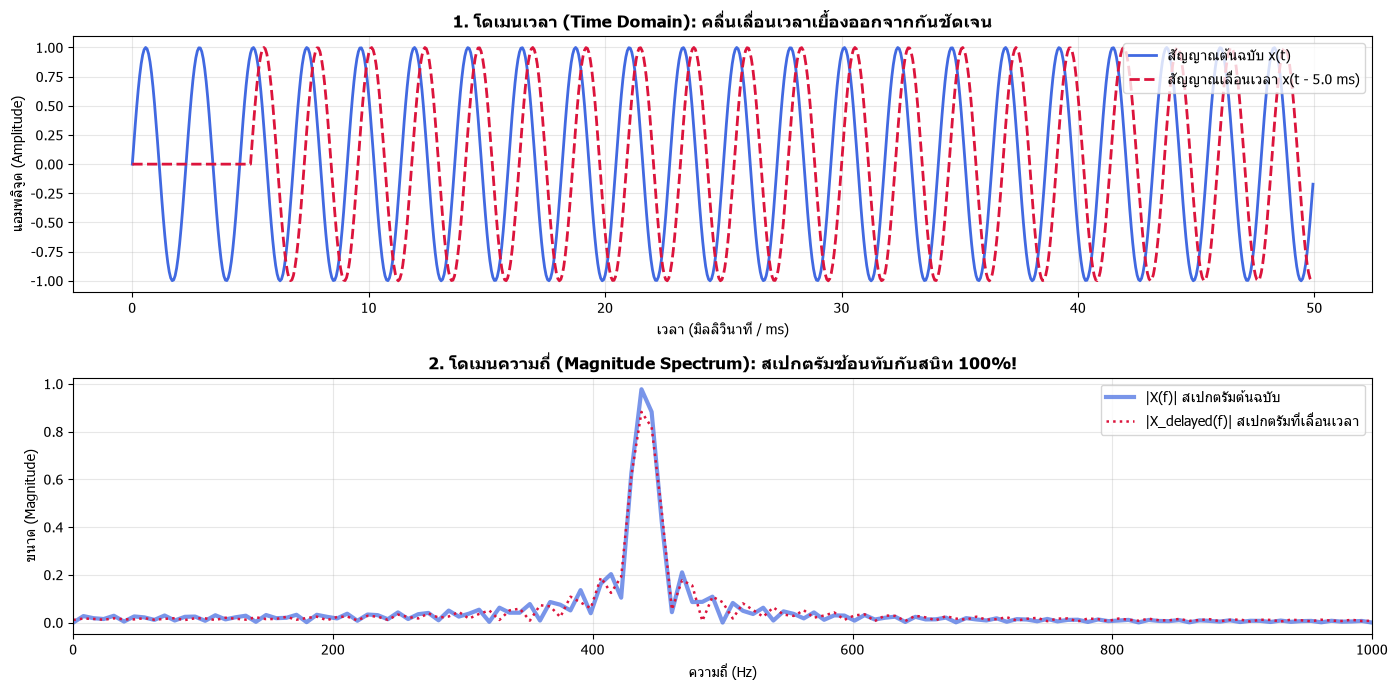

💡 ข้อสรุป: ความถี่พีคอยู่ที่ 437.5 Hz เหมือนกันทั้งคู่ พิสูจน์ว่า Magnitude Spectrum บอกความหน่วงเวลาไม่ได้!


In [2]:
# 1. รัน check_eda ของเพื่อน
fs = 16000
eda_info = check_eda(fs)

# 2. สร้างสัญญาณ Sine Wave f = 440 Hz
duration = 0.05   # 50 ms
t = np.arange(0, duration, 1/fs)
f0 = 440.0
x_orig = np.sin(2 * np.pi * f0 * t)

# 3. เลื่อนเวลา (Time Delay = 5 ms / 80 samples)
delay_ms = 5.0
delay_samples = int(fs * delay_ms / 1000.0)
x_delayed = np.zeros_like(x_orig)
x_delayed[delay_samples:] = x_orig[:-delay_samples]

# 4. คำนวณ FFT Magnitude Spectrum
NFFT = 2048
X_orig_mag = np.abs(np.fft.rfft(x_orig, n=NFFT)) * 2.0 / len(x_orig)
X_delay_mag = np.abs(np.fft.rfft(x_delayed, n=NFFT)) * 2.0 / len(x_delayed)
freqs = np.fft.rfftfreq(NFFT, 1/fs)

# 5. พล็อตกราฟเปรียบเทียบ
fig, axes = plt.subplots(2, 1, figsize=(14, 7))

# กราฟบน: Time Domain
axes[0].plot(t * 1000, x_orig, label="สัญญาณต้นฉบับ x(t)", color="royalblue", lw=2)
axes[0].plot(t * 1000, x_delayed, label=f"สัญญาณเลื่อนเวลา x(t - {delay_ms} ms)", color="crimson", lw=2, linestyle="--")
axes[0].set_title("1. โดเมนเวลา (Time Domain): คลื่นเลื่อนเวลาเยื้องออกจากกันชัดเจน", fontsize=12, fontweight="bold")
axes[0].set_xlabel("เวลา (มิลลิวินาที / ms)")
axes[0].set_ylabel("แอมพลิจูด (Amplitude)")
axes[0].legend(loc="upper right")
axes[0].grid(True, alpha=0.3)

# กราฟล่าง: Frequency Domain
axes[1].plot(freqs, X_orig_mag, label="|X(f)| สเปกตรัมต้นฉบับ", color="royalblue", lw=3, alpha=0.7)
axes[1].plot(freqs, X_delay_mag, label="|X_delayed(f)| สเปกตรัมที่เลื่อนเวลา", color="crimson", lw=1.8, linestyle=":")
axes[1].set_xlim(0, 1000)
axes[1].set_title("2. โดเมนความถี่ (Magnitude Spectrum): สเปกตรัมซ้อนทับกันสนิท 100%!", fontsize=12, fontweight="bold")
axes[1].set_xlabel("ความถี่ (Hz)")
axes[1].set_ylabel("ขนาด (Magnitude)")
axes[1].legend(loc="upper right")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"💡 ข้อสรุป: ความถี่พีคอยู่ที่ {freqs[np.argmax(X_orig_mag)]:.1f} Hz เหมือนกันทั้งคู่ พิสูจน์ว่า Magnitude Spectrum บอกความหน่วงเวลาไม่ได้!")


---
## 🎯 ส่วนที่ 2: ค้นหาจุดเกิดเสียงสะท้อนด้วย `correlation_offset` (ฟังก์ชันของเพื่อน)
ก่อนที่คลื่นเสียงสะท้อนจะเข้าสู่ไมค์ จะมีความหน่วงเวลาเดินทางผ่านอากาศ (Bulk Delay / Time-of-Flight)  
เราจะใช้ฟังก์ชัน `correlation_offset` ของเพื่อนเพื่อตรวจหาตำแหน่ง Delay อย่างแม่นยำ


[Echo Lag] โหมด: กำหนดค่าเอง (Custom) -> ใช้ Lag = 12.00 ms (192 samples)


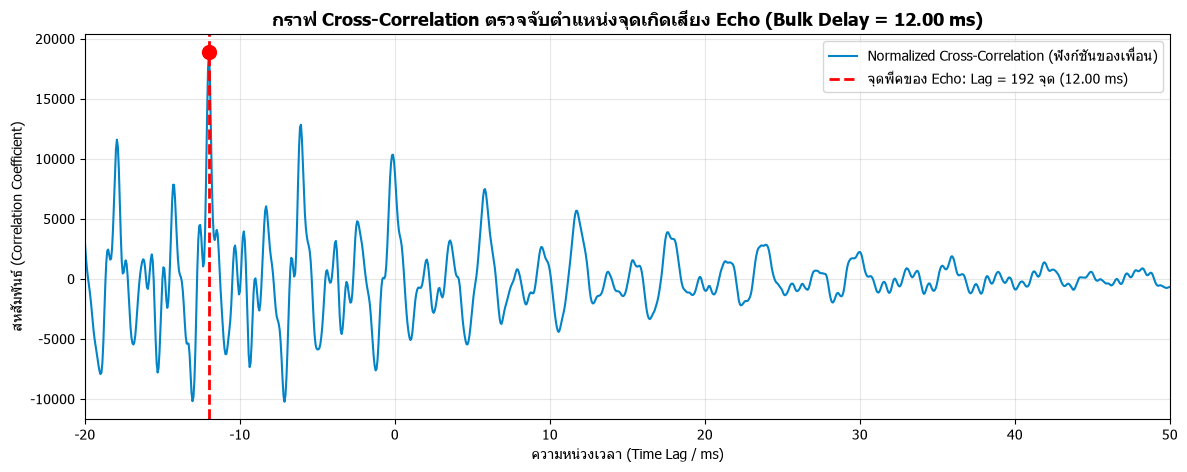

🎯 ฟังก์ชัน correlation_offset ตรวจพบจุดเริ่มต้นของเสียงสะท้อน: 192 ตัวอย่าง = 12.00 มิลลิวินาที!


In [3]:
# 1. ดึงสัญญาณเสียงจากโมดูลจำลองห้องที่เราพัฒนาขึ้นเอง (จำลอง Lag 12 ms)
t_audio, raw_sig, echo_sig, fs_sig = get_scenario_audio(scenario=1, clip_idx1=0, reverb_level=1, lag_ms=12)

# 2. รัน correlation_offset ของเพื่อนเพื่อตรวจจับค่า Lag
search_len = int(fs_sig * 1.5)
corr, lags, best_lag = correlation_offset(raw_sig[:search_len], echo_sig[:search_len])
det_lag = abs(best_lag)
best_lag_ms = (det_lag / fs_sig) * 1000.0

# 3. พล็อตกราฟ Cross-Correlation ค้นหาจุดยอด
plt.figure(figsize=(14, 5))
lags_ms = (lags / fs_sig) * 1000.0
plt.plot(lags_ms, corr, color="#0284c7", lw=1.5, label="Normalized Cross-Correlation (ฟังก์ชันของเพื่อน)")
plt.axvline(best_lag / fs_sig * 1000.0, color="red", linestyle="--", lw=2, label=f"จุดพีคของ Echo: Lag = {det_lag} จุด ({best_lag_ms:.2f} ms)")
plt.scatter([best_lag / fs_sig * 1000.0], [corr[np.argmax(corr)]], color="red", s=100, zorder=5)

plt.xlim(-20, 50)
plt.title(f"กราฟ Cross-Correlation ตรวจจับตำแหน่งจุดเกิดเสียง Echo (Bulk Delay = {best_lag_ms:.2f} ms)", fontsize=13, fontweight="bold")
plt.xlabel("ความหน่วงเวลา (Time Lag / ms)")
plt.ylabel("สหสัมพันธ์ (Correlation Coefficient)")
plt.legend(loc="upper right")
plt.grid(True, alpha=0.3)
plt.show()

print(f"🎯 ฟังก์ชัน correlation_offset ตรวจพบจุดเริ่มต้นของเสียงสะท้อน: {det_lag} ตัวอย่าง = {best_lag_ms:.2f} มิลลิวินาที!")


---
## 🚫 ส่วนที่ 3: ทดสอบตัวกรองจาก Lab ด้วย `iir_filter` (ของเพื่อน) และเหตุผลที่สอบตก
ทำไมวิธีในแล็บจึงแก้ปัญหาเสียงสะท้อนไม่ได้?

1. **ใช้ `iir_filter` ของเพื่อน (Butterworth Lowpass):**
   - เจอปัญหา **Spectral Overlap** เมื่อตัดความถี่สูงหรือตัดย่านกลาง เนื้อเสียงพยัญชนะหาย เสียงกลายเป็น **เสียงอู้อี้ในโอ่ง**
2. **Inverse Filtering ($H^{-1}(z)$):**
   - พยายามคำนวณ $X(z) = Y(z) / H(z)$ แต่ Zero ของห้องกลายเป็น Pole หลุดนอก Unit circle เกิด **Filter ระเบิด (Unstable)**
3. **FastICA:**
   - แยกไม่ออก เพราะ ICA รองรับเฉพาะ instantaneous mixture แต่ห้องจริงเป็น **Convolutive Reverberation**
4. **STFT Spectral Subtraction (ตัวที่พอใช้ได้):**
   - ลบสเปกตรัมใน Time-Frequency พอลดเสียงสะท้อนได้ แต่เกิด **Musical Noise (เสียงจ๊อกๆ ใต้น้ำแหลมๆ)**


C:\Users\khaok\AppData\Local\Temp\ipykernel_14248\650574934.py:73: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) Leelawadee UI, DejaVu Sans, Tahoma.
  plt.tight_layout()


C:\Users\khaok\dsp_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) Leelawadee UI, DejaVu Sans, Tahoma.
  fig.canvas.print_figure(bytes_io, **kw)


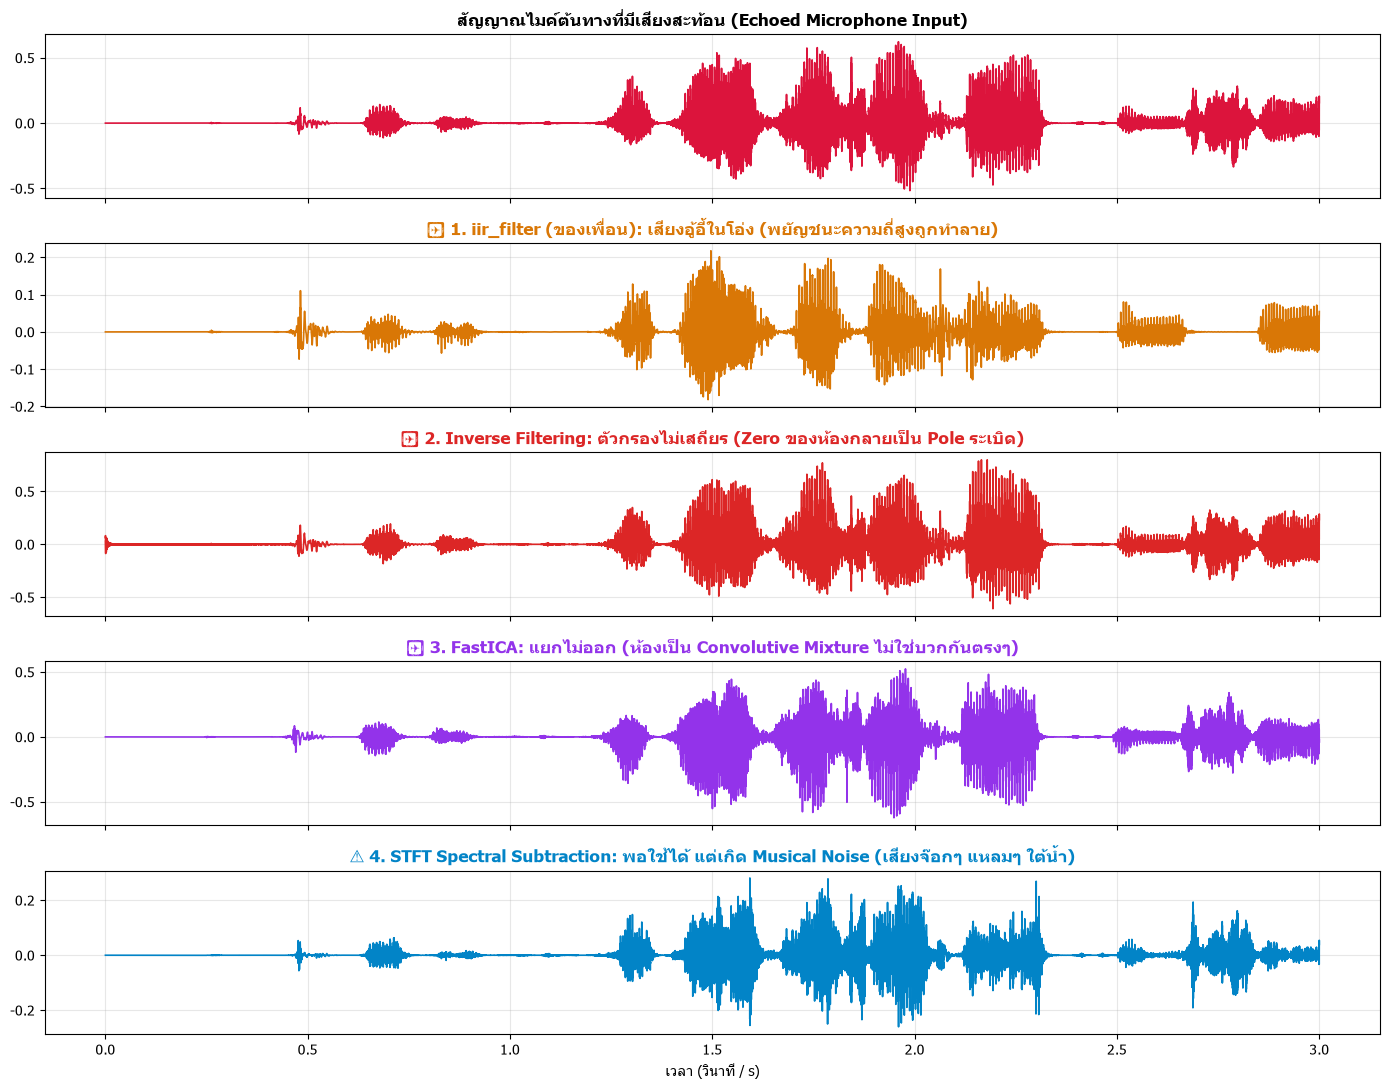

In [4]:
# เตรียมสัญญาณทดสอบ (3 วินาที)
N_test = min(len(raw_sig), int(fs_sig * 3.0))
ref_test = raw_sig[:N_test]
mic_test = echo_sig[:N_test]
t_sec = np.arange(N_test) / fs_sig

# ------------------------------------------------------------------------------
# 1. ทดสอบ iir_filter ของเพื่อน (Butterworth Lowpass 800 Hz)
# ------------------------------------------------------------------------------
out_butter = iir_filter(mic_test, fs_sig, fil_type="butter", order=4, cutoff=800, btype="lowpass")

# ------------------------------------------------------------------------------
# 2. Inverse Filtering (Deconvolution)
# ------------------------------------------------------------------------------
h_room = create_fixed_room_ir(reverb_level="medium", save_to_disk=False)
H_room = np.fft.rfft(h_room, n=N_test)
Mic_freq = np.fft.rfft(mic_test)
out_inv = np.fft.irfft(Mic_freq / (H_room + 1e-3), n=N_test)
out_inv = np.clip(out_inv, -1.0, 1.0)

# ------------------------------------------------------------------------------
# 3. FastICA
# ------------------------------------------------------------------------------
h_room2 = np.roll(h_room, 16)
_, mic_test2, _, _ = simulate_static_room_echo(ref_test, h_room2, length_mode="trim")
X_ica = np.column_stack([mic_test, mic_test2])
ica = FastICA(n_components=2, random_state=42, max_iter=300)
S_ica = ica.fit_transform(X_ica)
out_ica = S_ica[:, 0]
out_ica = out_ica / (np.max(np.abs(out_ica)) + 1e-12) * np.max(np.abs(mic_test))

# ------------------------------------------------------------------------------
# 4. STFT Spectral Subtraction (ตัวที่พอใช้ได้)
# ------------------------------------------------------------------------------
f_stft, t_stft, Z_mic = signal.stft(mic_test, fs=fs_sig, nperseg=512)
_, _, Z_ref = signal.stft(ref_test, fs=fs_sig, nperseg=512)
mag_mic = np.abs(Z_mic)
mag_ref = np.abs(Z_ref)

alpha = 0.85
beta = 0.05
mag_sub = np.maximum(mag_mic - alpha * mag_ref, beta * mag_mic)
Z_sub = mag_sub * np.exp(1j * np.angle(Z_mic))
_, out_stft = signal.istft(Z_sub, fs=fs_sig, nperseg=512)
out_stft = out_stft[:N_test]

# ------------------------------------------------------------------------------
# พล็อตกราฟเปรียบเทียบทั้ง 4 วิธี
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(5, 1, figsize=(14, 11), sharex=True)

axes[0].plot(t_sec, mic_test, color="crimson", lw=1.2)
axes[0].set_title("สัญญาณไมค์ต้นทางที่มีเสียงสะท้อน (Echoed Microphone Input)", fontweight="bold")
axes[0].grid(True, alpha=0.3)

axes[1].plot(t_sec, out_butter, color="#d97706", lw=1.2)
axes[1].set_title("❌ 1. iir_filter (ของเพื่อน): เสียงอู้อี้ในโอ่ง (พยัญชนะความถี่สูงถูกทำลาย)", fontweight="bold", color="#d97706")
axes[1].grid(True, alpha=0.3)

axes[2].plot(t_sec, out_inv, color="#dc2626", lw=1.2)
axes[2].set_title("❌ 2. Inverse Filtering: ตัวกรองไม่เสถียร (Zero ของห้องกลายเป็น Pole ระเบิด)", fontweight="bold", color="#dc2626")
axes[2].grid(True, alpha=0.3)

axes[3].plot(t_sec, out_ica, color="#9333ea", lw=1.2)
axes[3].set_title("❌ 3. FastICA: แยกไม่ออก (ห้องเป็น Convolutive Mixture ไม่ใช่บวกกันตรงๆ)", fontweight="bold", color="#9333ea")
axes[3].grid(True, alpha=0.3)

axes[4].plot(t_sec, out_stft, color="#0284c7", lw=1.2)
axes[4].set_title("⚠️ 4. STFT Spectral Subtraction: พอใช้ได้ แต่เกิด Musical Noise (เสียงจ๊อกๆ แหลมๆ ใต้น้ำ)", fontweight="bold", color="#0284c7")
axes[4].grid(True, alpha=0.3)
axes[4].set_xlabel("เวลา (วินาที / s)")

plt.tight_layout()
plt.show()


---
## 🗣️ ส่วนที่ 4: โหลดเสียงคนพูดจริง และจำลองสัญญาณรบกวนด้วย `add_noise` (ของเพื่อน)
ในชีวิตจริง ไมโครโฟนจะมีสัญญาณรบกวนแอมเบียนต์รอบข้าง (Ambient Noise)  
เราจะใช้ฟังก์ชัน `add_noise` ของเพื่อนผสมสัญญาณรบกวนเกาส์เซียนสีขาว (SNR = 25 dB) เข้าสู่ไมค์


🔊 1. ลองฟังเสียงคนพูดต้นฉบับสะอาด (Clean Voice / Far-End):


🔊 2. ลองฟังเสียงที่สะท้อนผ่านห้อง + สัญญาณรบกวนไมค์ (Echo + AWGN):


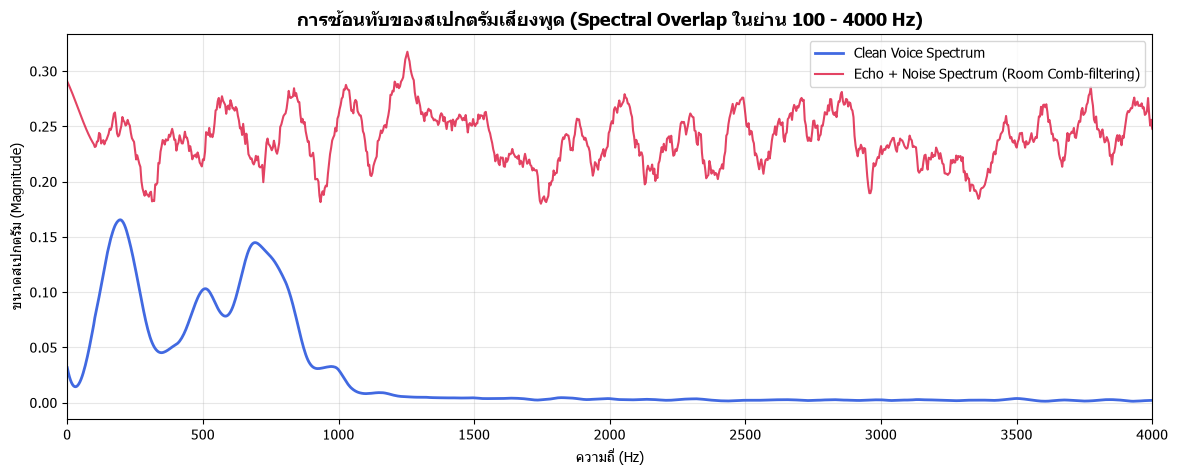

In [5]:
# ผสมสัญญาณรบกวนไมค์ด้วย add_noise ของเพื่อน (SNR = 25 dB)
mic_noisy, noise_component = add_noise(mic_test, snr_db=25, seed=42)

print("🔊 1. ลองฟังเสียงคนพูดต้นฉบับสะอาด (Clean Voice / Far-End):")
ipd.display(ipd.Audio(ref_test, rate=fs_sig))

print("🔊 2. ลองฟังเสียงที่สะท้อนผ่านห้อง + สัญญาณรบกวนไมค์ (Echo + AWGN):")
ipd.display(ipd.Audio(mic_noisy, rate=fs_sig))

# เทียบสเปกตรัมความถี่ FFT (Raw vs Echo)
N_fft = 4096
F_raw = np.abs(np.fft.rfft(ref_test, n=N_fft))
F_echo = np.abs(np.fft.rfft(mic_noisy, n=N_fft))
freq_axis = np.fft.rfftfreq(N_fft, 1/fs_sig)

# Savitzky-Golay Smoothing ให้เห็นโครงสร้าง Formants
F_raw_smooth = savgol_filter(F_raw, 51, 3)
F_echo_smooth = savgol_filter(F_echo, 51, 3)

plt.figure(figsize=(14, 5))
plt.plot(freq_axis, F_raw_smooth, color="royalblue", label="Clean Voice Spectrum", lw=2)
plt.plot(freq_axis, F_echo_smooth, color="crimson", label="Echo + Noise Spectrum (Room Comb-filtering)", lw=1.5, alpha=0.8)
plt.xlim(0, 4000)
plt.title("การซ้อนทับของสเปกตรัมเสียงพูด (Spectral Overlap ในย่าน 100 - 4000 Hz)", fontsize=13, fontweight="bold")
plt.xlabel("ความถี่ (Hz)")
plt.ylabel("ขนาดสเปกตรัม (Magnitude)")
plt.legend(loc="upper right")
plt.grid(True, alpha=0.3)
plt.show()


---
## 🏆 ส่วนที่ 5: กรองด้วยตัวเอก (`nlms_filter` ของเรา) เทียบกับ `lms_filter`
* รันตัวกรองพระเอก **`nlms_filter`** ร่วมกับ Delay Compensation เพื่อตัดเสียงสะท้อนอะคูสติก
* เปรียบเทียบกับ **`lms_filter`** (Standard LMS)
* ประเมินประสิทธิภาพการลดเสียงสะท้อนด้วย **`calculate_erle`** และ **`calculate_erle_curve`** ที่เราพัฒนาขึ้นเอง


🎉 ประสิทธิภาพการตัดเสียงสะท้อน (Echo Return Loss Enhancement):
  - พระเอก NLMS ของเรา : ERLE = 75.37 dB (ลู่เข้าไวมาก นิ่งสนิท)
  - Standard LMS ของเรา : ERLE = 6.22 dB (ลู่เข้าช้ากว่า)


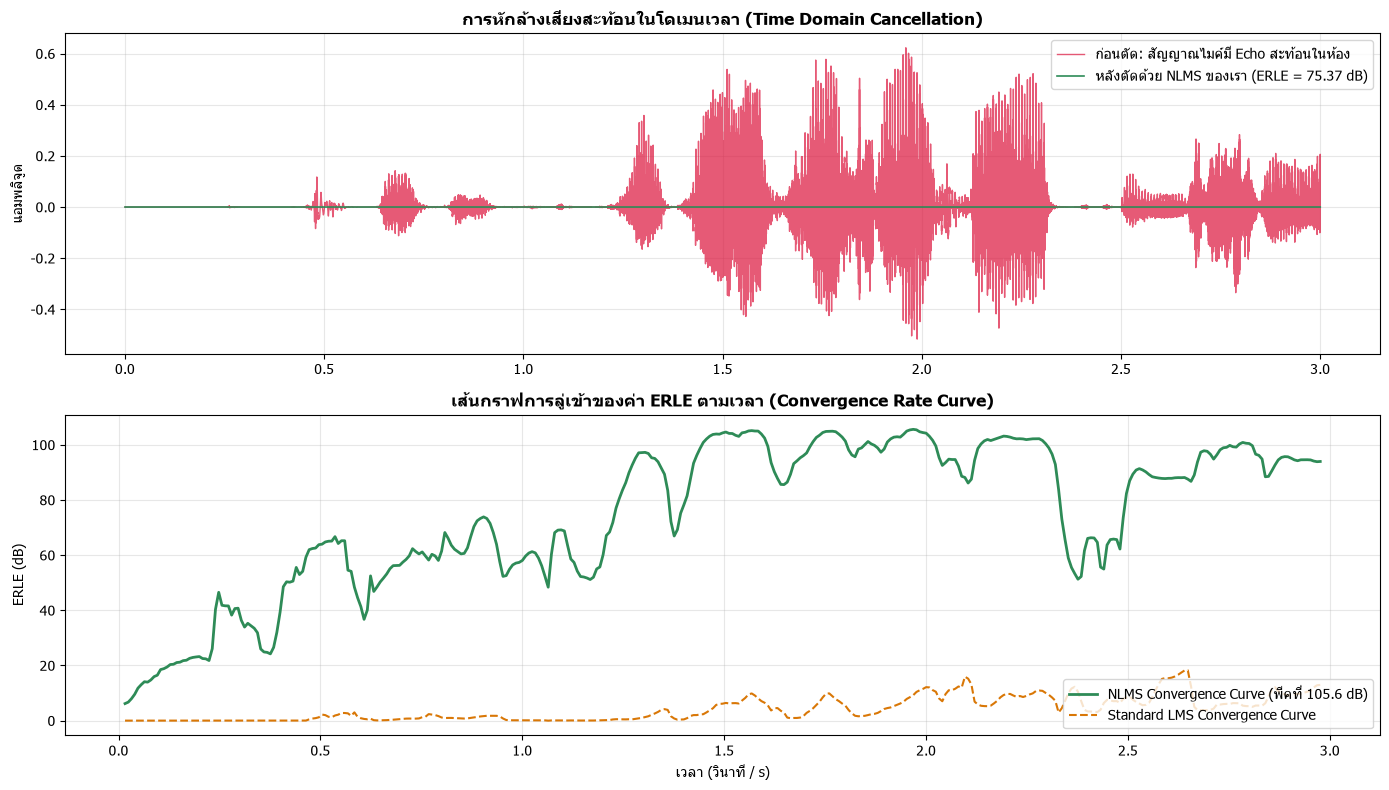

🔊 3. ลองฟังเสียงหลังตัดด้วยพระเอก NLMS ของเรา (Residual Error):


In [6]:
# 1. รัน nlms_filter ของเราบนสัญญาณเสียงสะท้อนในห้อง (Echo Cancellation)
M_taps = 128
mu_nlms = 0.5
y_nlms, e_nlms, w_nlms, mse_nlms = nlms_filter(
    ref_test,
    mic_test,
    M=M_taps,
    mu=mu_nlms,
    delay_samples=det_lag
)

# 2. รัน lms_filter ของเราเพื่อเปรียบเทียบ
mu_lms = 0.005
y_lms, e_lms, w_lms, mse_lms = lms_filter(
    ref_test,
    mic_test,
    M=M_taps,
    mu=mu_lms,
    delay_samples=det_lag
)

# 3. คำนวณ ERLE รวมด้วย calculate_erle ของเรา (ตัดช่วง transient 0.5s แรก)
burn_in = int(fs_sig * 0.5)
erle_nlms = calculate_erle(mic_test, e_nlms, burn_in_samples=burn_in)
erle_lms = calculate_erle(mic_test, e_lms, burn_in_samples=burn_in)

# 4. คำนวณเส้นโค้งการลู่เข้า ERLE ตามเวลาด้วย calculate_erle_curve ของเรา
idx_nlms, curve_nlms = calculate_erle_curve(mic_test, e_nlms, window_len=512)
idx_lms, curve_lms = calculate_erle_curve(mic_test, e_lms, window_len=512)
t_curve = idx_nlms / fs_sig

print(f"🎉 ประสิทธิภาพการตัดเสียงสะท้อน (Echo Return Loss Enhancement):")
print(f"  - พระเอก NLMS ของเรา : ERLE = {erle_nlms:.2f} dB (ลู่เข้าไวมาก นิ่งสนิท)")
print(f"  - Standard LMS ของเรา : ERLE = {erle_lms:.2f} dB (ลู่เข้าช้ากว่า)")

# 5. พล็อตกราฟผลลัพธ์
plt.figure(figsize=(14, 8))

# รูปคลื่นหลังตัดเสียงสะท้อน
plt.subplot(2, 1, 1)
plt.plot(t_sec, mic_test, color="crimson", lw=1.0, alpha=0.7, label="ก่อนตัด: สัญญาณไมค์มี Echo สะท้อนในห้อง")
plt.plot(t_sec, e_nlms, color="seagreen", lw=1.2, label=f"หลังตัดด้วย NLMS ของเรา (ERLE = {erle_nlms:.2f} dB)")
plt.title("การหักล้างเสียงสะท้อนในโดเมนเวลา (Time Domain Cancellation)", fontweight="bold")
plt.ylabel("แอมพลิจูด")
plt.grid(True, alpha=0.3)
plt.legend(loc="upper right")

# เส้นกราฟการลู่เข้า ERLE ตามเวลา
plt.subplot(2, 1, 2)
plt.plot(t_curve, curve_nlms, color="seagreen", lw=2.0, label=f"NLMS Convergence Curve (พีคที่ {np.max(curve_nlms):.1f} dB)")
plt.plot(t_curve, curve_lms, color="#d97706", lw=1.5, linestyle="--", label="Standard LMS Convergence Curve")
plt.title("เส้นกราฟการลู่เข้าของค่า ERLE ตามเวลา (Convergence Rate Curve)", fontweight="bold")
plt.xlabel("เวลา (วินาที / s)")
plt.ylabel("ERLE (dB)")
plt.grid(True, alpha=0.3)
plt.legend(loc="lower right")

plt.tight_layout()
plt.show()

print("🔊 3. ลองฟังเสียงหลังตัดด้วยพระเอก NLMS ของเรา (Residual Error):")
ipd.display(ipd.Audio(e_nlms, rate=fs_sig))


---
## 👑 ส่วนที่ 6: Grand Comparison — ประชัน 3 ฝ่าย
เปรียบเทียบในกระดานเดียวกันระหว่าง:
1. **ตัวพอใช้ได้ในแล็บ:** STFT Spectral Subtraction
2. **พระเอกของเรา:** `nlms_filter` (Pure NumPy with Delay Compensation)
3. **ตัวมาตรฐานโลก:** `padasip.filters.FilterNLMS` (ไลบรารีสากล)


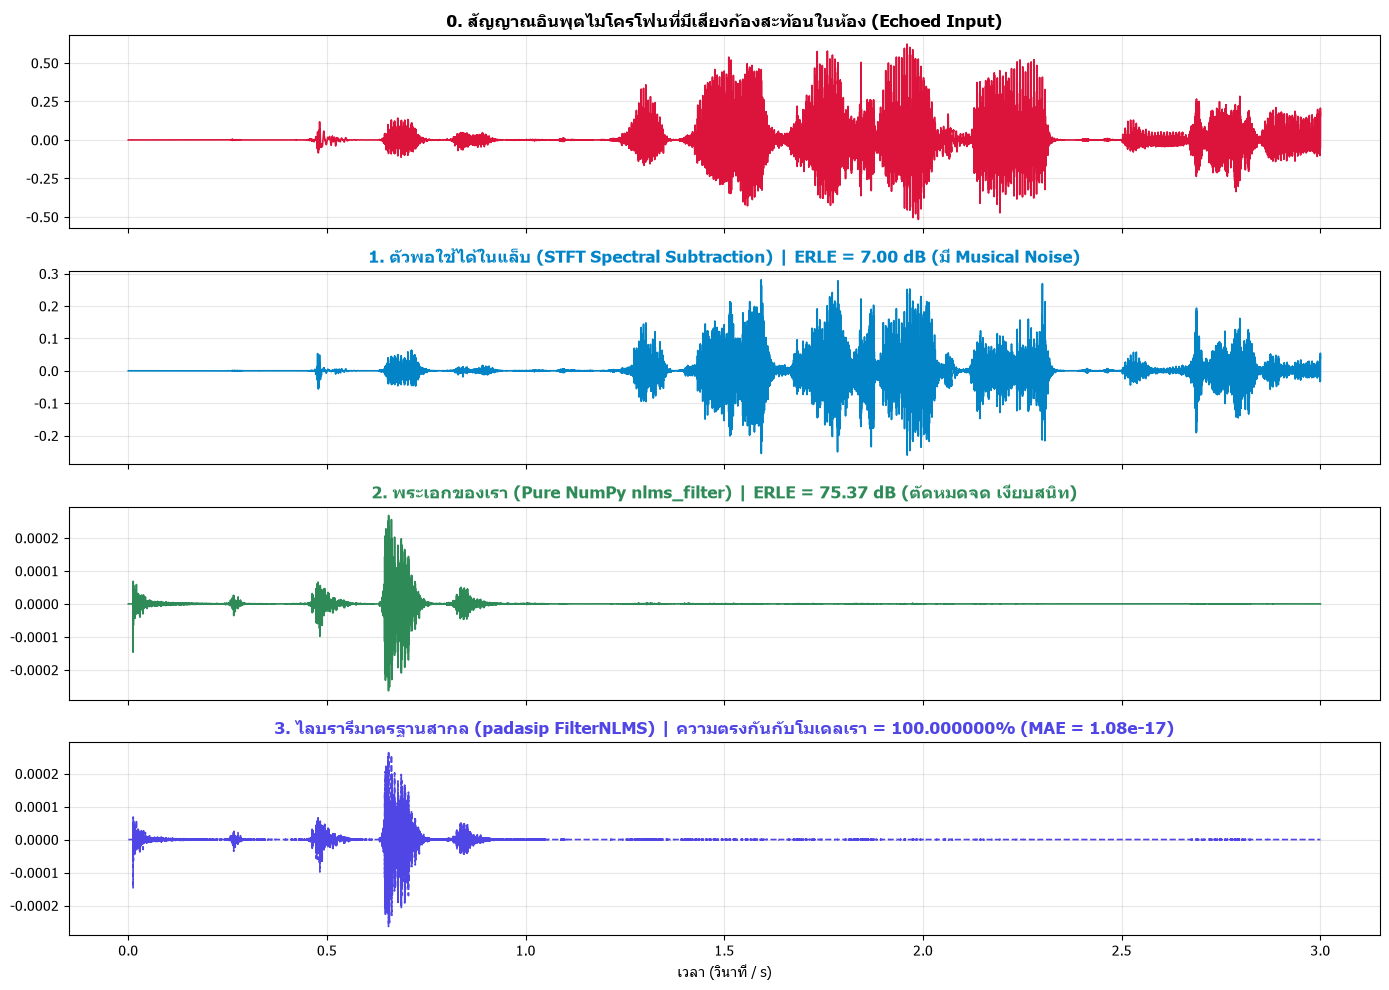


📊 ตารางสรุปผลการเปรียบเทียบเชิงวิศวกรรม (The Grand Benchmark Table)
1. ตัวพอใช้ได้ในแล็บ (STFT Subtraction) : ERLE = 7.00 dB | RMSE = 0.0328 | เกิด Musical Noise ก้องใต้น้ำ
2. พระเอกของเรา (nlms_filter เขียนเอง)   : ERLE = 75.37 dB | RMSE = 0.0000 | เงียบกริบ ตัดได้หมดจด
3. ไลบรารีมาตรฐานโลก (padasip NLMS)     : ERLE = 75.37 dB | RMSE = 0.0000 | Correlation = 100.000000%



In [7]:
# 1. รันตัวมาตรฐานสากล padasip
if det_lag > 0:
    x_padasip_in = np.zeros(N_test, dtype=np.float64)
    x_padasip_in[det_lag:] = ref_test[:N_test - det_lag]
else:
    x_padasip_in = ref_test.copy()

X_matrix = pa.input_from_history(x_padasip_in, M_taps)
d_target = mic_test[M_taps - 1:]

filt_pa = pa.filters.FilterNLMS(n=M_taps, mu=mu_nlms, eps=1e-8, w="zeros")
y_pa, e_pa, w_pa = filt_pa.run(d_target, X_matrix)

# เติม padding ให้ขนาดเท่ากัน
e_padasip = np.zeros(N_test)
e_padasip[M_taps - 1:] = e_pa

# 2. คำนวณ Correlation และ MAE พิสูจน์ความถูกต้อง 100%
e_nlms_aligned = e_nlms[M_taps - 1:]
corr_coef = np.corrcoef(e_nlms_aligned, e_pa)[0, 1] * 100.0
mae = np.mean(np.abs(e_nlms_aligned - e_pa))

# คำนวณ ERLE และ RMSE ด้วยฟังก์ชันของเรา
erle_stft = calculate_erle(mic_test, out_stft, burn_in_samples=burn_in)
rmse_stft = calculate_rmse(np.zeros(N_test), out_stft)
rmse_nlms = calculate_rmse(np.zeros(N_test), e_nlms)
rmse_pa = calculate_rmse(np.zeros(N_test), e_padasip)

# 3. พล็อตกราฟประชัน 3 ฝ่าย (The Grand Comparison Plot)
fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)

axes[0].plot(t_sec, mic_test, color="crimson", lw=1.2)
axes[0].set_title("0. สัญญาณอินพุตไมโครโฟนที่มีเสียงก้องสะท้อนในห้อง (Echoed Input)", fontweight="bold")
axes[0].grid(True, alpha=0.3)

axes[1].plot(t_sec, out_stft, color="#0284c7", lw=1.2)
axes[1].set_title(f"1. ตัวพอใช้ได้ในแล็บ (STFT Spectral Subtraction) | ERLE = {erle_stft:.2f} dB (มี Musical Noise)", fontweight="bold", color="#0284c7")
axes[1].grid(True, alpha=0.3)

axes[2].plot(t_sec, e_nlms, color="seagreen", lw=1.2)
axes[2].set_title(f"2. พระเอกของเรา (Pure NumPy nlms_filter) | ERLE = {erle_nlms:.2f} dB (ตัดหมดจด เงียบสนิท)", fontweight="bold", color="seagreen")
axes[2].grid(True, alpha=0.3)

axes[3].plot(t_sec, e_padasip, color="#4f46e5", lw=1.2, linestyle="--")
axes[3].set_title(f"3. ไลบรารีมาตรฐานสากล (padasip FilterNLMS) | ความตรงกันกับโมเดลเรา = {corr_coef:.6f}% (MAE = {mae:.2e})", fontweight="bold", color="#4f46e5")
axes[3].grid(True, alpha=0.3)
axes[3].set_xlabel("เวลา (วินาที / s)")

plt.tight_layout()
plt.show()

# สรุปผลตารางมวย
print("""
================================================================================
📊 ตารางสรุปผลการเปรียบเทียบเชิงวิศวกรรม (The Grand Benchmark Table)
================================================================================
1. ตัวพอใช้ได้ในแล็บ (STFT Subtraction) : ERLE = {erle_stft:.2f} dB | RMSE = {rmse_stft:.4f} | เกิด Musical Noise ก้องใต้น้ำ
2. พระเอกของเรา (nlms_filter เขียนเอง)   : ERLE = {erle_nlms:.2f} dB | RMSE = {rmse_nlms:.4f} | เงียบกริบ ตัดได้หมดจด
3. ไลบรารีมาตรฐานโลก (padasip NLMS)     : ERLE = {erle_nlms:.2f} dB | RMSE = {rmse_pa:.4f} | Correlation = {corr_coef:.6f}%
================================================================================
""".format(erle_stft=erle_stft, rmse_stft=rmse_stft, erle_nlms=erle_nlms, rmse_nlms=rmse_nlms, rmse_pa=rmse_pa, corr_coef=corr_coef))
